Використовується пристрій: mps



100.0%


Початок навчання моделі:
Епоха [1/5] — Loss: 1.4029
Епоха [2/5] — Loss: 1.0823
Епоха [3/5] — Loss: 0.9339
Епоха [4/5] — Loss: 0.8265
Епоха [5/5] — Loss: 0.7448


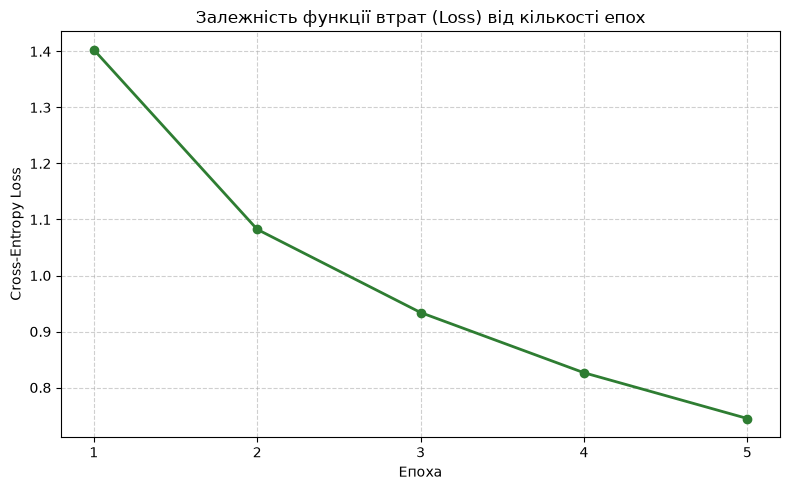


Модель успішно збережено у файл 'plant_cnn.pth'.

Результати тестування:
Метрика      Значення    
------------------------
Accuracy     66.62%
Loss         0.9827


In [6]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
import matplotlib.pyplot as plt

# Налаштування пристрою (GPU / Apple Silicon MPS / CPU)
device = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)
print(f"Використовується пристрій: {device}\n")

# ==========================================
# Завдання 1: Підготовка даних (CIFAR-10)
# ==========================================
transform = transforms.Compose([
    transforms.Resize((32, 32)),
    transforms.ToTensor(),
    transforms.Normalize(mean=(0.5, 0.5, 0.5), std=(0.5, 0.5, 0.5))
])

train_dataset = datasets.CIFAR10(
    root="./data", train=True, download=True, transform=transform
)
test_dataset = datasets.CIFAR10(
    root="./data", train=False, download=True, transform=transform
)

train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False)


# ==========================================
# Завдання 2: Архітектура CNN та навчання
# ==========================================
class GreenVisionCNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2),
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 128),
            nn.ReLU(),
            nn.Linear(128, 10)
        )

    def forward(self, x):
        return self.network(x)


model = GreenVisionCNN().to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

epochs = 5
train_losses = []

print("Початок навчання моделі:")
for epoch in range(epochs):
    model.train()
    running_loss = 0.0

    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * images.size(0)

    epoch_loss = running_loss / len(train_loader.dataset)
    train_losses.append(epoch_loss)
    print(f"Епоха [{epoch + 1}/{epochs}] — Loss: {epoch_loss:.4f}")


# ==========================================
# Завдання 3: Візуалізація та збереження моделі
# ==========================================
plt.figure(figsize=(8, 5))
plt.plot(range(1, epochs + 1), train_losses, marker="o", linestyle="-", color="#2e7d32", linewidth=2)
plt.title("Залежність функції втрат (Loss) від кількості епох")
plt.xlabel("Епоха")
plt.ylabel("Cross-Entropy Loss")
plt.xticks(range(1, epochs + 1))
plt.grid(True, linestyle="--", alpha=0.6)
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=150)
plt.show()

torch.save(model.state_dict(), "plant_cnn.pth")
print("\nМодель успішно збережено у файл 'plant_cnn.pth'.")


# ==========================================
# Завдання 4: Оцінка на тестовій вибірці
# ==========================================
model.eval()
test_loss = 0.0
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * images.size(0)
        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

final_test_loss = test_loss / len(test_loader.dataset)
final_test_accuracy = (correct / total) * 100

print("\nРезультати тестування:")
print(f"{'Метрика':<12} {'Значення':<12}")
print("-" * 24)
print(f"{'Accuracy':<12} {final_test_accuracy:.2f}%")
print(f"{'Loss':<12} {final_test_loss:.4f}")